# Демонстрации к лекции 6: линейный поиск, доверительная область, сопряжённые градиенты

Ноутбук — для самостоятельной проверки после пары: всё, что на лекции было формулой или картинкой, здесь считается кодом, а числа конспекта печатаются рядом с ожидаемыми. Читается сверху вниз; каждая часть начинается с «что проверяем и что должны увидеть».

- **(0)** три задачи введения: Ньютон на арктангенсе — обещание параболы против правды, порог старта $1.39$; Химмельблау; цепь из 400 грузов;
- **(a)** линейный поиск (раздел 2): $\varphi(\alpha)$, Армихо и Вольфе на Розенброке, backtracking $1\to\tfrac12\to\tfrac14\to\tfrac18$;
- **(b)** доверительная область (раздел 3): модельная задача, точка Коши и dogleg, $25$ итераций на Розенброке с таблицей $\Delta_k,\rho_k$, только точка Коши — $14\,110$;
- **(c)** сопряжённые градиенты (раздел 4): эллипс за $2$ шага, цепь за $N/2$, Newton-CG в $1000$ переменных;
- **(d)** биография цепи и таблица методов SciPy (разделы 4–5).
- **(e)** подробности линейного поиска (§2.2, §3.3): сильный Вольфе своими руками, $s^\top y$ у BFGS, цепь и масштаб $H_0$, ловушка седла.

Конспект: [`lecture06.md`](lecture06.md). Запуск: `uv run jupyter lab` в корне репозитория. Пакеты — `numpy`, `scipy`, `matplotlib`; CasADi — только в семинаре.

In [1]:
%matplotlib inline

import time

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import minimize, rosen as rosen_nd, rosen_der, rosen_hess_prod

BLUE, ORANGE, AQUA, YELLOW, RED, VIOLET = "#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e34948", "#4a3aa7"
GRAY, INK = "#8a8985", "#0b0b0b"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.2, "legend.frameon": False})


# ---------------------------------------------------------------- методы (те же, что в demo06 / l6helpers.py)
def armijo(f, x, fx, g, p, c1=1e-4, alpha=1.0, maxit=60):
    """Backtracking по Армихо: делим alpha пополам, пока f(x + alpha p) > f(x) + c1 alpha g^T p.
    Возвращает (alpha, f(x + alpha p), число вычислений f)."""
    slope = g @ p
    for k in range(1, maxit + 1):
        f_new = f(x + alpha * p)
        if f_new <= fx + c1 * alpha * slope:
            return alpha, f_new, k
        alpha /= 2
    return alpha, f_new, maxit


def wolfe(f, grad, x, p, fx, g, c1=1e-4, c2=0.9, alpha=1.0, maxit=40):
    """Шаг по сильным условиям Вольфе (Nocedal & Wright, алгоритмы 3.5-3.6).
    Фаза 1: alpha удваивается, пока не накроет интервал с подходящим шагом;
    фаза 2 (zoom): интервал делится пополам. Если из-за округления подходящий шаг
    не находится, возвращается лучший найденный шаг с Армихо.
    Возвращает (alpha, f_new, g_new, число вычислений f и grad)."""
    phi0, dphi0 = fx, g @ p
    lo, phi_lo = 0.0, phi0
    nf, hi = 0, None
    for i in range(maxit):
        xa = x + alpha * p; phi = f(xa); ga = grad(xa); dphi = ga @ p; nf += 1
        if phi > phi0 + c1 * alpha * dphi0 or (i > 0 and phi >= phi_lo):
            hi = alpha; break
        if abs(dphi) <= -c2 * dphi0:
            return alpha, phi, ga, nf
        if dphi >= 0:
            hi, lo, phi_lo = lo, alpha, phi; break
        lo, phi_lo = alpha, phi
        alpha *= 2
    else:
        return alpha, phi, ga, nf
    for _ in range(maxit):                         # zoom: lo — лучший шаг с Армихо, hi — другой край
        alpha = 0.5 * (lo + hi)
        xa = x + alpha * p; phi = f(xa); ga = grad(xa); dphi = ga @ p; nf += 1
        if phi > phi0 + c1 * alpha * dphi0 or phi >= phi_lo:
            hi = alpha
        else:
            if abs(dphi) <= -c2 * dphi0:
                return alpha, phi, ga, nf
            if dphi * (hi - lo) >= 0:
                hi = lo
            lo, phi_lo = alpha, phi
        if abs(hi - lo) < 1e-14 * max(1.0, lo):
            break
    xa = x + lo * p
    return lo, f(xa), grad(xa), nf + 1


def newton_ls(f, grad, hess, x0, tol=1e-10, maxit=200, c1=1e-4, shift="ascent"):
    """Ньютон с линейным поиском по Армихо (Л5 §3.4). Сдвиг гессиана H + (|lambda_min| + 1e-3) I:
    shift="ascent" — только если направление Ньютона не спуск (как в Л5 и ДЗ 3);
    shift="always" — всякий раз, когда lambda_min <= 1e-3 («модифицированный Ньютон», как в IPOPT).
    Возвращает (x, итераций, путь)."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]; n = len(x)
    for k in range(maxit):
        g = grad(x)
        if np.linalg.norm(g) <= tol:
            return x, k, np.array(path)
        H = hess(x)
        if shift == "always":
            lam_min = np.linalg.eigvalsh(H)[0]
            if lam_min <= 1e-3:
                H = H + (abs(lam_min) + 1e-3) * np.eye(n)
            p = -np.linalg.solve(H, g)
        else:
            p = -np.linalg.solve(H, g)
            if g @ p >= 0:
                lam_min = np.linalg.eigvalsh(H)[0]
                p = -np.linalg.solve(H + (abs(lam_min) + 1e-3) * np.eye(n), g)
        a, _, _ = armijo(f, x, f(x), g, p, c1=c1)
        x = x + a * p; path.append(x.copy())
    return x, maxit, np.array(path)


def bfgs(f, grad, x0, tol=1e-6, maxit=10_000, line="armijo", c1=1e-4, c2=0.9, Q=None, scale_H0=False):
    """BFGS с H_0 = I (Л5 §4.3). Длина шага: line="armijo" — backtracking (как в Л5),
    "wolfe" — сильные условия Вольфе, "exact" — точный шаг на квадратичной 1/2 x^T Q x + b^T x.
    scale_H0=True — после первого шага H_0 <- (s^T y / y^T y) I (Nocedal & Wright, (6.20)).
    Обновление пропускается, если s^T y <= 1e-12 (как в Л5).
    Возвращает (x, итераций, путь, вычислений f, история (s^T y, cos угла между s и y))."""
    x = np.asarray(x0, float).copy(); n = len(x)
    H = np.eye(n); g = grad(x); fx = f(x); nf = 1
    path = [x.copy()]; sy = []
    for k in range(maxit):
        if np.linalg.norm(g) <= tol:
            return x, k, np.array(path), nf, np.array(sy)
        p = -H @ g
        if line == "armijo":
            a, fx_new, m = armijo(f, x, fx, g, p, c1=c1); nf += m
            g_new = grad(x + a * p)
        elif line == "wolfe":
            a, fx_new, g_new, m = wolfe(f, grad, x, p, fx, g, c1=c1, c2=c2); nf += m
        else:
            a = -(g @ p) / (p @ Q @ p)
            fx_new = f(x + a * p); g_new = grad(x + a * p); nf += 1
        s = a * p; y = g_new - g
        sy.append((s @ y, (s @ y) / (np.linalg.norm(s) * np.linalg.norm(y) + 1e-300)))
        if k == 0 and scale_H0 and s @ y > 0:
            H = (s @ y) / (y @ y) * np.eye(n)
        if s @ y > 1e-12:
            rho = 1.0 / (s @ y); I = np.eye(n)
            H = (I - rho * np.outer(s, y)) @ H @ (I - rho * np.outer(y, s)) + rho * np.outer(s, s)
        x = x + s; g = g_new; fx = fx_new
        path.append(x.copy())
    return x, maxit, np.array(path), nf, np.array(sy)


def cauchy_point(g, B, Delta):
    """Точка Коши: минимум модели вдоль -g внутри шара радиуса Delta."""
    gBg = g @ B @ g; gn = np.linalg.norm(g)
    tau = 1.0 if gBg <= 0 else min(gn ** 3 / (Delta * gBg), 1.0)
    return -tau * Delta / gn * g


def dogleg(g, B, Delta):
    """Ломаная Пауэлла (B > 0): от нуля к минимуму модели вдоль -g, затем к точке Ньютона."""
    pB = -np.linalg.solve(B, g)
    if np.linalg.norm(pB) <= Delta:
        return pB
    pU = -(g @ g) / (g @ B @ g) * g
    if np.linalg.norm(pU) >= Delta:
        return -Delta / np.linalg.norm(g) * g
    d = pB - pU
    a, b, c = d @ d, 2 * pU @ d, pU @ pU - Delta ** 2
    return pU + (-b + np.sqrt(b * b - 4 * a * c)) / (2 * a) * d


def tr_exact(g, B, Delta):
    """Точное решение подзадачи min g^T p + 1/2 p^T B p при ||p|| <= Delta (Moré–Sorensen):
    p = -(B + lam I)^{-1} g, lam >= 0, B + lam I >= 0, lam (Delta - ||p||) = 0.
    lam — делением пополам по собственному разложению B (годится для небольших n)."""
    lam, V = np.linalg.eigh(B); gt = V.T @ g

    def p_of(mu):
        return -V @ (gt / (lam + mu))
    if lam[0] > 0 and np.linalg.norm(p_of(0.0)) <= Delta:
        return p_of(0.0)
    lo = max(0.0, -lam[0]); hi = lo + np.linalg.norm(g) / Delta + 1.0
    if np.linalg.norm(p_of(lo + 1e-12 * max(1.0, lo))) < Delta:      # «трудный случай»
        p = p_of(lo + 1e-12 * max(1.0, lo))
        return p + np.sqrt(max(Delta ** 2 - p @ p, 0.0)) * V[:, 0]
    for _ in range(200):
        mid = 0.5 * (lo + hi)
        if np.linalg.norm(p_of(mid)) > Delta:
            lo = mid
        else:
            hi = mid
    return p_of(hi)


def trust_region(f, grad, hess, x0, step="exact", Delta=1.0, Delta_max=10.0, eta=0.1, tol=1e-6, maxit=20_000):
    """Доверительная область (Nocedal & Wright, алгоритм 4.1): модель m(p) = f + g^T p + 1/2 p^T B p,
    B — гессиан; шаг — step = "exact" | "dogleg" | "cauchy". rho = (f(x) - f(x+p)) / (m(0) - m(p)):
    rho < 1/4 -> Delta/4; rho > 3/4 и шаг на границе -> min(2 Delta, Delta_max); шаг принят при rho > eta.
    Возвращает (x, итераций, путь, история [(x_k, p_k, Delta_k, rho_k, принят)])."""
    x = np.asarray(x0, float).copy(); fx = f(x); path = [x.copy()]; hist = []
    for k in range(maxit):
        g = grad(x)
        if np.linalg.norm(g) <= tol:
            return x, k, np.array(path), hist
        B = hess(x)
        if step == "exact":
            p = tr_exact(g, B, Delta)
        elif step == "dogleg" and np.linalg.eigvalsh(B)[0] > 0:
            p = dogleg(g, B, Delta)
        else:
            p = cauchy_point(g, B, Delta)
        pred = -(g @ p + 0.5 * p @ B @ p)
        f_new = f(x + p)
        rho = (fx - f_new) / pred
        hist.append((x.copy(), p.copy(), Delta, rho, rho > eta))
        if rho < 0.25:
            Delta = 0.25 * Delta
        elif rho > 0.75 and np.linalg.norm(p) >= 0.99 * Delta:
            Delta = min(2 * Delta, Delta_max)
        if rho > eta:
            x = x + p; fx = f_new; path.append(x.copy())
    return x, maxit, np.array(path), hist


def cg(Av, b, x0, tol=1e-6, maxit=None):
    """Линейные сопряжённые градиенты для A x = b (A > 0); A задана только умножением Av(v).
    Останов: ||A x - b|| <= tol. Возвращает (x, итераций, история норм невязки)."""
    x = np.asarray(x0, float).copy(); r = Av(x) - b; d = -r; hist = [np.linalg.norm(r)]
    for k in range(maxit or 10 * len(x)):
        if hist[-1] <= tol:
            return x, k, np.array(hist)
        Ad = Av(d); a = (r @ r) / (d @ Ad)
        x = x + a * d; r_new = r + a * Ad
        beta = (r_new @ r_new) / (r @ r); d = -r_new + beta * d; r = r_new
        hist.append(np.linalg.norm(r))
    return x, maxit, np.array(hist)


def newton_cg(f, grad, hessp, x0, tol=1e-6, maxit=500, c1=1e-4):
    """Неточный Ньютон (Newton-CG): систему H p = -g решаем CG до невязки eta_k ||g||,
    eta_k = min(0.5, sqrt(||g||)); на отрицательной кривизне CG останавливается (если это
    первая итерация — берём p = -g); длина шага — Армихо. hessp(x, v) = H(x) v.
    Возвращает (x, итераций, умножений H v, история (||g_k||, внутренних итераций))."""
    x = np.asarray(x0, float).copy(); nmv = 0; hist = []
    for k in range(maxit):
        g = grad(x); gn = np.linalg.norm(g)
        if gn <= tol:
            hist.append((gn, 0))
            return x, k, nmv, hist
        eta = min(0.5, np.sqrt(gn)); z = np.zeros_like(x); r = g.copy(); d = -r; inner = 0
        for j in range(10 * len(x)):
            Hd = hessp(x, d); nmv += 1; inner += 1; dHd = d @ Hd
            if dHd <= 0:
                if j == 0:
                    z = -g
                break
            a = (r @ r) / dHd; z = z + a * d; r_new = r + a * Hd
            if np.linalg.norm(r_new) <= eta * gn:
                break
            beta = (r_new @ r_new) / (r @ r); d = -r_new + beta * d; r = r_new
        hist.append((gn, inner))
        a, _, _ = armijo(f, x, f(x), g, z, c1=c1)
        x = x + a * z
    return x, maxit, nmv, hist


def gd(f, grad, x0, alpha=None, tol=1e-6, maxit=100_000, c=1e-4):
    """Градиентный спуск (Л4): alpha=None — backtracking по Армихо, иначе постоянный шаг."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]
    for k in range(maxit):
        g = grad(x)
        if np.linalg.norm(g) <= tol:
            return x, k, np.array(path)
        if alpha is None:
            a, _, _ = armijo(f, x, f(x), g, -g, c1=c)
        else:
            a = alpha
        x = x - a * g; path.append(x.copy())
    return x, maxit, np.array(path)


def newton(grad, hess, x0, tol=1e-10, maxit=50):
    """Чистый метод Ньютона (Л5): шаг всегда 1."""
    x = np.asarray(x0, float).copy(); path = [x.copy()]
    for k in range(maxit):
        g = grad(x)
        if np.linalg.norm(g) <= tol:
            return x, k, np.array(path)
        x = x - np.linalg.solve(hess(x), g); path.append(x.copy())
    return x, maxit, np.array(path)


# ---------------------------------------------------------------- задачи
def rosen(x):
    return (1 - x[0]) ** 2 + 100 * (x[1] - x[0] ** 2) ** 2


def rosen_grad(x):
    return np.array([-2 * (1 - x[0]) - 400 * x[0] * (x[1] - x[0] ** 2), 200 * (x[1] - x[0] ** 2)])


def rosen_hess(x):
    return np.array([[2 - 400 * x[1] + 1200 * x[0] ** 2, -400 * x[0]], [-400 * x[0], 200.0]])


X0_ROSEN = np.array([-1.2, 1.0])


def him(x):
    return (x[0] ** 2 + x[1] - 11) ** 2 + (x[0] + x[1] ** 2 - 7) ** 2


def him_grad(x):
    a, b = x[0] ** 2 + x[1] - 11, x[0] + x[1] ** 2 - 7
    return np.array([4 * x[0] * a + 2 * b, 2 * a + 4 * x[1] * b])


def him_hess(x):
    return np.array([[12 * x[0] ** 2 + 4 * x[1] - 42, 4 * x[0] + 4 * x[1]],
                     [4 * x[0] + 4 * x[1], 4 * x[0] + 12 * x[1] ** 2 - 26]])


def make_chain(N, D=70.0, g=9.81):
    """Цепь без пола (Л1 §7.3): E(v) = 1/2 v^T H v + b^T v + const, v = (y_1..y_N, z_1..z_N)."""
    m = 4.0 / N
    K = 2 * np.eye(N) - np.eye(N, k=1) - np.eye(N, k=-1)
    H = np.kron(np.eye(2), D * K)
    b = np.zeros(2 * N)
    b[0] -= D * (-2.0); b[N - 1] -= D * 2.0
    b[N] -= D * 1.0; b[2 * N - 1] -= D * 1.0
    b[N:] += m * g
    v0 = np.r_[np.linspace(-2, 2, N + 2)[1:-1], np.ones(N)]

    def unpack(v):
        return np.r_[-2.0, v[:N], 2.0], np.r_[1.0, v[N:], 1.0]

    def energy(v):
        y, z = unpack(v)
        return 0.5 * D * np.sum(np.diff(y) ** 2 + np.diff(z) ** 2) + m * g * np.sum(z[1:-1])

    def grad_E(v):
        return H @ v + b
    return energy, grad_E, H, b, v0, unpack


def gd_chain_count(N, tol=1e-6):
    """Число итераций спуска с шагом 1/L на цепи — точно, через собственные числа:
    ||g_k||^2 = sum lam_i^2 e_i^2 (1 - lam_i/L)^(2k). Возвращает (итераций, kappa, функция ||g_k||)."""
    _, _, H, b, v0, _ = make_chain(N)
    lam, V = np.linalg.eigh(H); L = lam[-1]
    e0 = V.T @ (v0 - np.linalg.solve(H, -b))

    def gnorm(k):
        return np.sqrt(np.sum((lam * e0 * (1 - lam / L) ** k) ** 2))
    lo, hi = 0, 1
    while gnorm(hi) > tol:
        hi *= 2
    while hi - lo > 1:
        mid = (lo + hi) // 2
        lo, hi = (mid, hi) if gnorm(mid) > tol else (lo, mid)
    return hi, lam[-1] / lam[0], gnorm


def f_arctan(x):
    return x * np.arctan(x) - 0.5 * np.log1p(x * x)


def rosen_contour(ax, xlim=(-2, 2), ylim=(-1, 3), n=400):
    X, Y = np.meshgrid(np.linspace(*xlim, n), np.linspace(*ylim, n))
    F = (1 - X) ** 2 + 100 * (Y - X ** 2) ** 2
    ax.contour(X, Y, F, levels=np.geomspace(0.3, 2000, 14), colors=GRAY, linewidths=0.6, alpha=0.7)
    ax.plot(1, 1, "*", color=RED, ms=16, zorder=7)
    ax.set(xlim=xlim, ylim=ylim, xlabel="$x_1$", ylabel="$x_2$")


def him_contour(ax, lim=6.0, n=400, levels=None):
    X, Y = np.meshgrid(np.linspace(-lim, lim, n), np.linspace(-lim, lim, n))
    F = (X ** 2 + Y - 11) ** 2 + (X + Y ** 2 - 7) ** 2
    ax.contour(X, Y, F, levels=levels if levels is not None else np.geomspace(0.5, 800, 14),
               colors=GRAY, linewidths=0.6, alpha=0.7)


## (0) Три задачи введения

**Что проверяем.** Числа введения. Чистый Ньютон для $f(x)=x\arctan x-\tfrac12\ln(1+x^2)$ из $x_0=2$ улетает: $2\to-3.54\to13.95\to-279\to1.2\cdot10^5\to-2.3\cdot10^{10}$. С Армихо — $5$ итераций, $\alpha=\tfrac12,1,1,1,1$. Почему так — картинка `img/00_atan_newton.png` конспекта: парабола-модель в $x_0=2$ обещает $-1.65$, а получаем $3.28$; при больших $\lvert x_k\rvert$ ошибка возводится в квадрат, $\lvert x_{k+1}\rvert\approx\tfrac{\pi}{2}x_k^2$; порог старта $1.39$.

In [2]:
x = 2.0; seq = [x]
for _ in range(5):
    x = x - np.arctan(x) * (1 + x * x)          # f' = arctan x, f'' = 1/(1+x^2)
    seq.append(x)
print("чистый Ньютон:", [f"{v:.4g}" for v in seq])

x = np.array([2.0]); alphas = []
while abs(np.arctan(x[0])) > 1e-10:
    g = np.array([np.arctan(x[0])]); p = -g * (1 + x[0] ** 2)
    a, _, _ = armijo(lambda z: f_arctan(z[0]), x, f_arctan(x[0]), g, p)
    x = x + a * p; alphas.append(a)
print(f"с Армихо: {len(alphas)} итераций, шаги {alphas}   (в конспекте: 5 итераций, 1/2, 1, 1, 1, 1)")

чистый Ньютон: ['2', '-3.536', '13.95', '-279.3', '1.22e+05', '-2.339e+10']
с Армихо: 5 итераций, шаги [0.5, 1.0, 1.0, 1.0, 1.0]   (в конспекте: 5 итераций, 1/2, 1, 1, 1, 1)


**Обещание модели против правды.** Парабола-модель в $x_0=2$: $m(x)=f(2)+\arctan 2\,(x-2)+\tfrac{1}{10}(x-2)^2$. Её вершина — $x_1=-3.54$. Что она там обещает, что там на самом деле и что даёт половина шага? Затем — показатель степени ошибки $\log_{10}\lvert x_k\rvert$ (удваивается, но растёт) и отношение $\lvert x_{k+1}\rvert/x_k^2$, которое стремится к $\pi/2$.

In [3]:
x0, x1 = seq[0], seq[1]
m = lambda x: f_arctan(x0) + np.arctan(x0) * (x - x0) + 0.5 / (1 + x0**2) * (x - x0) ** 2
x_half = x0 - 0.5 * np.arctan(x0) * (1 + x0**2)
print(f"f(x0) = {f_arctan(x0):.3f}, модель обещала m(x1) = {m(x1):.3f}, на самом деле f(x1) = {f_arctan(x1):.3f}, "
      f"половина шага: x = {x_half:.3f}, f = {f_arctan(x_half):.3f}   (в конспекте: 1.41, -1.65, 3.28, 0.27)")
print("log10|x_k|:        ", [f"{np.log10(abs(v)):.2f}" for v in seq], "  (в конспекте: 0.3, 0.55, 1.1, 2.4, 5.1, 10.4)")
print("|x_{k+1}| / x_k^2: ", [f"{abs(seq[k + 1]) / seq[k]**2:.4f}" for k in range(5)], f"  -> pi/2 = {np.pi / 2:.4f}")

f(x0) = 1.410, модель обещала m(x1) = -1.655, на самом деле f(x1) = 3.278, половина шага: x = -0.768, f = 0.271   (в конспекте: 1.41, -1.65, 3.28, 0.27)
log10|x_k|:         ['0.30', '0.55', '1.14', '2.45', '5.09', '10.37']   (в конспекте: 0.3, 0.55, 1.1, 2.4, 5.1, 10.4)
|x_{k+1}| / x_k^2:  ['0.8839', '1.1159', '1.4353', '1.5637', '1.5708']   -> pi/2 = 1.5708


**Порог старта.** Чистый Ньютон сходится из $\lvert x_0\rvert<x^\ast$ и расходится из $\lvert x_0\rvert>x^\ast$, где из $x^\ast$ шаг переносит ровно в $-x^\ast$: $(1+x^2)\arctan x=2x$. В конспекте $x^\ast\approx1.39$.

In [4]:
from scipy.optimize import brentq

thr = brentq(lambda x: (1 + x * x) * np.arctan(x) - 2 * x, 1.0, 2.0)
print(f"порог x* = {thr:.4f}   (в конспекте: 1.39)")
with np.errstate(over="ignore", invalid="ignore"):
    for x0_ in [1.39, 1.40]:
        x = x0_
        for _ in range(30):
            x = x - np.arctan(x) * (1 + x * x)
        print(f"  чистый Ньютон из {x0_}: через 30 шагов x = {x:.3g}")

порог x* = 1.3917   (в конспекте: 1.39)
  чистый Ньютон из 1.39: через 30 шагов x = 0
  чистый Ньютон из 1.4: через 30 шагов x = nan


**Предскажите до запуска.** Сколько делений пополам понадобится на первом шаге, если стартовать из $x_0=100$? Чем дальше старт, тем длиннее шаг Ньютона: $\lvert p\rvert=\arctan(x_0)(1+x_0^2)$.

In [5]:
x0 = 100.0
x = np.array([x0]); first = None; k = 0
while abs(np.arctan(x[0])) > 1e-10:
    g = np.array([np.arctan(x[0])]); p = -g * (1 + x[0] ** 2)
    a, _, m = armijo(lambda z: f_arctan(z[0]), x, f_arctan(x[0]), g, p)
    first = first or (a, m)
    x = x + a * p; k += 1
print(f"из x0 = {x0:g}: {k} итераций; первый шаг α = {first[0]:g} после {first[1] - 1} делений пополам; |p| = {np.arctan(x0) * (1 + x0**2):.0f}")

из x0 = 100: 7 итераций; первый шаг α = 0.0078125 после 7 делений пополам; |p| = 15610


Ответ: $\alpha=1/128$ — семь делений, потому что полный шаг Ньютона длиной $\approx15\,600$ в сотни раз длиннее разумного. Дальше — полные шаги и квадратичная сходимость.

**Химмельблау и цепь.** Куда приходит чистый Ньютон из нескольких стартов (бассейны всей сетки — картинка 07 конспекта) и сколько итераций у спуска и CG на цепи из $400$ грузов (число спуска считается точно через собственные числа, как в Л5).

In [6]:
for x0 in [(0.0, 0.0), (0.58, 2.15), (-0.5, -1.0), (4.0, 4.0)]:
    x, k, _ = newton(him_grad, him_hess, x0)
    lam = np.linalg.eigvalsh(him_hess(x))
    kind = "минимум" if lam[0] > 0 else ("максимум" if lam[1] < 0 else "седло")
    print(f"старт {x0}: чистый Ньютон за {k} итераций в ({x[0]:.3f}, {x[1]:.3f}) — {kind}")

k_gd, kappa, _ = gd_chain_count(400)
_, _, H400, b400, v400, _ = make_chain(400)
_, k_cg, _ = cg(lambda v: H400 @ v, -b400, v400)
print(f"цепь N = 400: κ = {kappa:.0f}, спуск 1/L — {k_gd} итераций, CG — {k_cg}   (в конспекте: 937 503 и 200)")

старт (0.0, 0.0): чистый Ньютон за 5 итераций в (-0.271, -0.923) — максимум
старт (0.58, 2.15): чистый Ньютон за 5 итераций в (0.087, 2.884) — седло
старт (-0.5, -1.0): чистый Ньютон за 4 итераций в (-0.271, -0.923) — максимум
старт (4.0, 4.0): чистый Ньютон за 7 итераций в (3.000, 2.000) — минимум


цепь N = 400: κ = 65170, спуск 1/L — 937503 итераций, CG — 200   (в конспекте: 937 503 и 200)


**Доверительная область на функции введения.** Добавим вторую координату: $f(x)=x_1\arctan x_1-\tfrac12\ln(1+x_1^2)+\tfrac12x_2^2$, старт $(2,1)$. Модель в старте — параболоид с вершиной в $(-3.54,0)$: там она обещает $-1.65$, а на самом деле $f=3.28$. Ньютон прыгает в вершину и улетает, как в одномерном случае; доверительная область с $\Delta_0=1$ приходит в $(0,0)$ за $6$ итераций (картинка `img/05_tr_model.png` конспекта, §3.1).

In [7]:
f2 = lambda x: x[0] * np.arctan(x[0]) - 0.5 * np.log1p(x[0] ** 2) + 0.5 * x[1] ** 2   # функция введения + x2^2/2
g2 = lambda x: np.array([np.arctan(x[0]), x[1]])                                       # градиент
h2 = lambda x: np.diag([1 / (1 + x[0] ** 2), 1.0])                                    # гессиан
x0 = np.array([2.0, 1.0])
pN = -np.linalg.solve(h2(x0), g2(x0))                                                 # шаг Ньютона — в вершину модели
print(f"вершина модели {(x0 + pN).round(2)}: модель обещает {f2(x0) + 0.5 * g2(x0) @ pN:.2f}, на деле f = {f2(x0 + pN):.2f}")
x, k, path, hist = trust_region(f2, g2, h2, x0, step="exact")
print(f"доверительная область: {k} итераций → {x.round(6)}; путь: {[tuple(q.round(2)) for q in path[:4]]} …")
xk, p, D, rho, acc = hist[0]
print(f"первый шаг (Δ = {D:g}): модель {f2(xk) + g2(xk) @ p + 0.5 * p @ h2(xk) @ p:.2f}, на деле {f2(xk + p):.2f}, "
      f"ρ = {rho:.2f} — {'принят' if acc else 'отвергнут'};  в конспекте: 0.65, 0.67, 0.98")

вершина модели [-3.54  0.  ]: модель обещает -1.65, на деле f = 3.28
доверительная область: 6 итераций → [-0.  0.]; путь: [(np.float64(2.0), np.float64(1.0)), (np.float64(1.13), np.float64(0.52)), (np.float64(-0.79), np.float64(0.0)), (np.float64(0.29), np.float64(0.0))] …
первый шаг (Δ = 1): модель 0.65, на деле 0.67, ρ = 0.98 — принят;  в конспекте: 0.65, 0.67, 0.98


## (a) Линейный поиск: Армихо, Вольфе, backtracking

**Что проверяем.** Числа §2.1–2.2: на Розенброке в $x_1$ (первая итерация Ньютона из $(-1.2,1)$) шаг Ньютона длиной $4.95$ ведёт в $f=1412$; Армихо выполнено при $\alpha\le0.176$, Вольфе ($c_2=0.9$) — при $0.044\le\alpha\le0.176$; backtracking пробует $1,\tfrac12,\tfrac14$ и принимает $\tfrac18$.

In [8]:
x1 = X0_ROSEN - np.linalg.solve(rosen_hess(X0_ROSEN), rosen_grad(X0_ROSEN))   # x1: первая итерация Ньютона из (-1.2, 1)
p1 = -np.linalg.solve(rosen_hess(x1), rosen_grad(x1))                           # p1: шаг Ньютона в x1 (длина 4.95)
phi = lambda a: rosen(x1 + a * p1)              # разрез f вдоль шага: phi(alpha) = f(x1 + alpha * p1)
dphi = lambda a: rosen_grad(x1 + a * p1) @ p1   # производная разреза по правилу сложной функции: grad f(x1 + alpha p1) . p1
print(f"x1 = {x1.round(4)}, |p1| = {np.linalg.norm(p1):.3f}, φ(0) = {phi(0):.3f}, φ(1) = {phi(1):.1f}, φ'(0) = {dphi(0):.3f}   (в конспекте: 4.95, 4.73, 1412, -8.43)")

al = np.linspace(0, 0.3, 30001)                                        # сетка длин шага alpha
arm = np.array([phi(a) <= phi(0) + 1e-4 * a * dphi(0) for a in al])   # правило Армихо: phi под прямой с наклоном c1 phi'(0), c1 = 1e-4
wol = arm & np.array([dphi(a) >= 0.9 * dphi(0) for a in al])          # плюс условие кривизны Вольфе: наклон стал положе, c2 = 0.9
print(f"Армихо: α ≤ {al[arm].max():.3f};  Вольфе: {al[wol].min():.3f} ≤ α ≤ {al[wol].max():.3f}   (в конспекте: 0.176; 0.044–0.176)")

for a in [1, 0.5, 0.25, 0.125]:                                        # backtracking: alpha = 1, затем пополам, пока Армихо не выполнено
    ok = phi(a) <= phi(0) + 1e-4 * a * dphi(0)
    print(f"  α = {a:<6g} φ = {phi(a):9.3f}  Армихо: {'да — принят' if ok else 'нет'}")

x1 = [-1.1753  1.3807], |p1| = 4.951, φ(0) = 4.732, φ(1) = 1411.8, φ'(0) = -8.433   (в конспекте: 4.95, 4.73, 1412, -8.43)


Армихо: α ≤ 0.176;  Вольфе: 0.044 ≤ α ≤ 0.176   (в конспекте: 0.176; 0.044–0.176)
  α = 1      φ =  1411.845  Армихо: нет
  α = 0.5    φ =    89.749  Армихо: нет
  α = 0.25   φ =     8.395  Армихо: нет
  α = 0.125  φ =     4.087  Армихо: да — принят


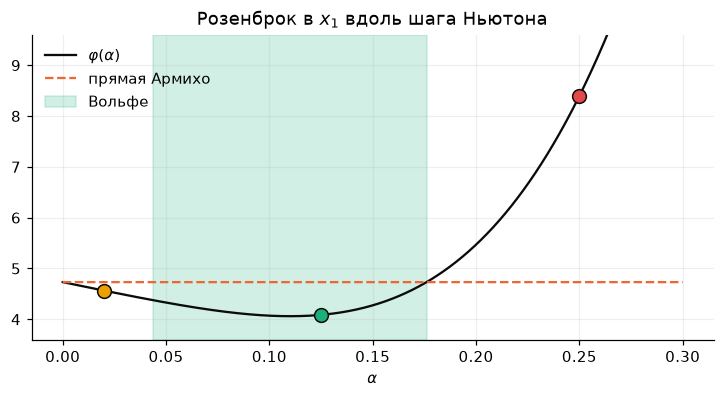

In [9]:
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.plot(al, [phi(a) for a in al], color=INK, label=r"$\varphi(\alpha)$")                 # разрез phi(alpha)
ax.plot(al, phi(0) + 1e-4 * al * dphi(0), "--", color=ORANGE, label="прямая Армихо")       # прямая Армихо: phi(0) + c1 alpha phi'(0)
ax.axvspan(al[wol].min(), al[wol].max(), color=AQUA, alpha=0.2, label="Вольфе")            # допустимые по Вольфе шаги
for a, col in [(0.02, YELLOW), (0.125, AQUA), (0.25, RED)]:                                 # три кандидата из «вопроса залу»
    ax.plot(a, phi(a), "o", color=col, ms=9, mec=INK)                                        #   0.02 — только Армихо, 0.125 — оба, 0.25 — ни одного
ax.set(ylim=(3.6, 9.6), xlabel=r"$\alpha$", title="Розенброк в $x_1$ вдоль шага Ньютона")
ax.legend(); plt.show()

## (b) Доверительная область: $\rho$, точка Коши, dogleg

**Что проверяем.** Модельная задача $g=(3,4)$, $B=\operatorname{diag}(1,2)$: точка Ньютона $(-3,-2)$, модель в ней $-8.5$; при $\Delta=1$ точка Коши $(-0.6,-0.8)$, модель $-4.18$. Затем метод целиком на Розенброке: $25$ итераций, из них $3$ пробных шага отвергнуты.

In [10]:
g_t, B_t = np.array([3.0, 4.0]), np.diag([1.0, 2.0])
m = lambda p: g_t @ p + 0.5 * p @ B_t @ p
pN = -np.linalg.solve(B_t, g_t); pU = -(g_t @ g_t) / (g_t @ B_t @ g_t) * g_t
print(f"точка Ньютона {pN}, |pN| = {np.linalg.norm(pN):.3f}, m = {m(pN):.3f};  минимум вдоль -g: {pU.round(3)}, |pU| = {np.linalg.norm(pU):.3f}")
for D in [1.0, 2.0, 3.0, 4.0]:
    pc, pd, pe = cauchy_point(g_t, B_t, D), dogleg(g_t, B_t, D), tr_exact(g_t, B_t, D)
    print(f"Δ = {D}: Коши {pc.round(3)} m = {m(pc):7.3f} | dogleg {pd.round(3)} m = {m(pd):7.3f} | точный {pe.round(3)} m = {m(pe):7.3f}")

точка Ньютона [-3. -2.], |pN| = 3.606, m = -8.500;  минимум вдоль -g: [-1.829 -2.439], |pU| = 3.049
Δ = 1.0: Коши [-0.6 -0.8] m =  -4.180 | dogleg [-0.6 -0.8] m =  -4.180 | точный [-0.677 -0.736] m =  -4.204
Δ = 2.0: Коши [-1.2 -1.6] m =  -6.720 | dogleg [-1.2 -1.6] m =  -6.720 | точный [-1.494 -1.33 ] m =  -6.917
Δ = 3.0: Коши [-1.8 -2.4] m =  -7.620 | dogleg [-1.8 -2.4] m =  -7.620 | точный [-2.413 -1.783] m =  -8.280
Δ = 4.0: Коши [-1.829 -2.439] m =  -7.622 | dogleg [-3. -2.] m =  -8.500 | точный [-3. -2.] m =  -8.500


Точный шаг всегда не хуже dogleg, dogleg — не хуже точки Коши; при $\Delta\ge\lVert p_N\rVert=3.61$ все три — точка Ньютона. **Предскажите до запуска:** сколько итераций сделает доверительная область на Розенброке, если брать *только* точку Коши? (Подсказка: это спуск с точным шагом, обрезанным шаром.)

In [11]:
for step in ["exact", "dogleg", "cauchy"]:
    t0 = time.perf_counter()
    x, k, path, hist = trust_region(rosen, rosen_grad, rosen_hess, X0_ROSEN, step=step)
    rej = sum(not h[4] for h in hist)
    print(f"{step:7s}: {k:6d} итераций, отвергнуто {rej}, x = {x.round(6)}, {time.perf_counter() - t0:.1f} с")
print("в конспекте: 25 (3 отвергнуты), 24, 14 110; спуск с backtracking из Л4 — 13 756")

exact  :     25 итераций, отвергнуто 3, x = [1. 1.], 0.0 с
dogleg :     24 итераций, отвергнуто 3, x = [1. 1.], 0.0 с
cauchy :  14110 итераций, отвергнуто 2, x = [0.999999 0.999998], 0.2 с
в конспекте: 25 (3 отвергнуты), 24, 14 110; спуск с backtracking из Л4 — 13 756


**Таблица $\Delta_k$ и $\rho_k$** для точного шага: на итерации $1$ — тот самый выброс Л5 — шаг обрезан до $\Delta=1$, и всё равно $\rho<0$: шаг отвергнут, радиус вчетверо меньше.

In [12]:
x, k, path, hist = trust_region(rosen, rosen_grad, rosen_hess, X0_ROSEN, step="exact")
print(" k    Δ_k      ρ_k     шаг     |p|")
for i, (xk, p, D, rho, acc) in enumerate(hist):
    print(f"{i:2d}  {D:7.4f}  {rho:7.3f}   {'принят ' if acc else 'ОТВЕРГ.'}  {np.linalg.norm(p):.3f}")

 k    Δ_k      ρ_k     шаг     |p|
 0   1.0000    1.003   принят   0.381
 1   1.0000   -0.430   ОТВЕРГ.  1.000
 2   0.2500    1.014   принят   0.250
 3   0.5000    0.846   принят   0.500
 4   1.0000    1.281   принят   0.383
 5   1.0000    1.359   принят   0.244
 6   1.0000    1.096   принят   0.288
 7   1.0000    1.297   принят   0.117
 8   1.0000   -0.706   ОТВЕРГ.  0.316
 9   0.2500    0.479   принят   0.250
10   0.2500    1.137   принят   0.101
11   0.2500    0.062   ОТВЕРГ.  0.250
12   0.0625    1.006   принят   0.062
13   0.1250    0.956   принят   0.125
14   0.2500    1.031   принят   0.211
15   0.2500    1.244   принят   0.128
16   0.2500    0.524   принят   0.250
17   0.2500    1.110   принят   0.097
18   0.2500    0.222   принят   0.250
19   0.0625    1.033   принят   0.054
20   0.0625    0.985   принят   0.062
21   0.1250    1.088   принят   0.064
22   0.1250    1.041   принят   0.012
23   0.1250    1.004   принят   0.002
24   0.1250    1.000   принят   0.000


**Отрицательная кривизна.** Из ловушки $(0.58,2.15)$ доверительная область приходит в минимум $(3,2)$ — за $7$ итераций, без всякого сдвига: в шаре минимум модели есть всегда.

In [13]:
x, k, path, hist = trust_region(him, him_grad, him_hess, (0.58, 2.15), step="exact", tol=1e-10)
print(f"доверительная область: {k} итераций → {x.round(6)}; λ_min гессиана в старте = {np.linalg.eigvalsh(him_hess(np.array([0.58, 2.15])))[0]:.1f}")

доверительная область: 7 итераций → [3. 2.]; λ_min гессиана в старте = -31.3


## (c) Сопряжённые градиенты

**Что проверяем.** На эллипсе $\tfrac12(x_1^2+50x_2^2)$ из $(50,1)$ CG сходится за $2$ шага (спуск с точным шагом — $567$, Л4); направления сопряжены: $d_1^\top Ad_0=0$. На цепи — ровно $N/2$ итераций.

In [14]:
A = np.diag([1.0, 50.0]); x = np.array([50.0, 1.0]); r = A @ x; d = -r; ds = []
for k in range(2):
    a = (r @ r) / (d @ A @ d); x = x + a * d; r_new = r + a * A @ d
    ds.append(d.copy()); d = -r_new + (r_new @ r_new) / (r @ r) * d; r = r_new
    print(f"итерация {k + 1}: x = {x.round(10)}")
print(f"сопряжённость d1^T A d0 = {ds[1] @ A @ ds[0]:.2e}")

итерация 1: x = [48.03921569 -0.96078431]
итерация 2: x = [0. 0.]
сопряжённость d1^T A d0 = -1.64e-11


**Предскажите до запуска:** сколько итераций CG на цепи из $400$ грузов ($800$ переменных)? А если стартовать не с прямой между концами, а со случайной точки?

In [15]:
for N in [10, 20, 40, 80, 160, 400]:
    _, gE_N, H_N, b_N, v0_N, _ = make_chain(N)
    _, k_sym, _ = cg(lambda v: H_N @ v, -b_N, v0_N)
    v_rand = v0_N + 0.1 * np.random.default_rng(2026).standard_normal(2 * N)
    _, k_rand, _ = cg(lambda v: H_N @ v, -b_N, v_rand)
    print(f"N = {N:3d}: CG из прямой — {k_sym:3d} (N/2 = {N // 2}), из случайного старта — {k_rand}")

N =  10: CG из прямой —   5 (N/2 = 5), из случайного старта — 10
N =  20: CG из прямой —  10 (N/2 = 10), из случайного старта — 20
N =  40: CG из прямой —  20 (N/2 = 20), из случайного старта — 40
N =  80: CG из прямой —  40 (N/2 = 40), из случайного старта — 80


N = 160: CG из прямой —  80 (N/2 = 80), из случайного старта — 160
N = 400: CG из прямой — 200 (N/2 = 200), из случайного старта — 400


Из прямой — ровно $N/2$: горизонтальная часть ошибки нулевая, вертикальная симметрична и задевает только $N/2$ собственных векторов. Из случайного старта задеты все собственные векторы — итераций больше.

**Newton-CG в $1000$ переменных.** Розенброк из SciPy (`rosen`, `rosen_der`, `rosen_hess_prod`), старт $0.5\cdot\mathbf1$. Наш `newton_cg` берёт гессиан только как произведение на вектор. Ожидаем: $47$ итераций и $225$ произведений; SciPy `Newton-CG` — $54$ и $291$; `L-BFGS-B` — $88$ (с `ftol=0`).

In [16]:
x0 = np.full(1000, 0.5)
x, k, nmv, hist = newton_cg(rosen_nd, rosen_der, rosen_hess_prod, x0)
print(f"наш Newton-CG: {k} итераций, {nmv} произведений H v, f = {rosen_nd(x):.1e}")
r = minimize(rosen_nd, x0, jac=rosen_der, hessp=rosen_hess_prod, method="Newton-CG", options={"xtol": 1e-8})
print(f"SciPy Newton-CG: {r.nit} итераций, {r.nhev} произведений H v")
for ftol in [None, 0.0]:
    opts = {"gtol": 1e-6, "maxiter": 10_000} | ({} if ftol is None else {"ftol": ftol})
    r = minimize(rosen_nd, x0, jac=rosen_der, method="L-BFGS-B", options=opts)
    print(f"L-BFGS-B, ftol = {'по умолчанию' if ftol is None else 0}: {r.nit} итераций, |∇f| = {np.linalg.norm(rosen_der(r.x)):.1e}")

наш Newton-CG: 47 итераций, 225 произведений H v, f = 8.8e-21
SciPy Newton-CG: 54 итераций, 291 произведений H v
L-BFGS-B, ftol = по умолчанию: 78 итераций, |∇f| = 1.0e-03
L-BFGS-B, ftol = 0: 88 итераций, |∇f| = 1.4e-06


## (d) Биография цепи и методы SciPy

**Что проверяем.** Цепь $N=40$ одним списком: спуск $10\,575$, BFGS с точным шагом $20$, CG $20$, Ньютон $1$, доверительная область с CG Стейхауга (SciPy `trust-ncg`) — $13$. Затем таблица методов SciPy на Розенброке и критерии останова.

In [17]:
E, gE, H, b, v0, unpack = make_chain(40)
k_gd, _, _ = gd_chain_count(40)
_, k_b, _, _, _ = bfgs(E, gE, v0, line="exact", Q=H)
_, k_cg, _ = cg(lambda v: H @ v, -b, v0)
r = minimize(E, v0, jac=gE, hessp=lambda v, p: H @ p, method="trust-ncg", options={"gtol": 1e-6})
print(f"спуск 1/L {k_gd} | BFGS точный шаг {k_b} | CG {k_cg} | Ньютон 1 | trust-ncg {r.nit}")

спуск 1/L 10575 | BFGS точный шаг 20 | CG 20 | Ньютон 1 | trust-ncg 13


In [18]:
rows = []
for m in ["BFGS", "L-BFGS-B", "CG", "Newton-CG", "trust-exact", "dogleg", "trust-ncg", "trust-krylov"]:
    kw = dict(jac=rosen_grad)
    if m in ("Newton-CG", "trust-exact", "dogleg", "trust-ncg", "trust-krylov"):
        kw["hess"] = rosen_hess
    opts = {"xtol": 1e-8} if m == "Newton-CG" else {"gtol": 1e-6}
    if m == "L-BFGS-B":
        opts["ftol"] = 0.0
    r = minimize(rosen, X0_ROSEN, method=m, options=opts, **kw)
    rows.append((m, r.nit, r.nfev, np.linalg.norm(rosen_grad(r.x))))
print(f"{'метод':13s} итераций  вычислений f   |∇f| в конце")
for m, nit, nfev, gn in rows:
    print(f"{m:13s} {nit:7d}  {nfev:12d}   {gn:.1e}")
print("в конспекте: BFGS 33/40, L-BFGS-B 37, CG 37/80, Newton-CG 85, trust-exact 25, dogleg 24, trust-ncg 29, trust-krylov 38")

метод         итераций  вычислений f   |∇f| в конце
BFGS               33            40   2.6e-08
L-BFGS-B           37            45   3.8e-08
CG                 37            80   5.0e-11
Newton-CG          85           107   3.2e-10
trust-exact        25            26   6.4e-09
dogleg             24            25   1.3e-09
trust-ncg          29            30   2.7e-07
trust-krylov       38            39   5.2e-09
в конспекте: BFGS 33/40, L-BFGS-B 37, CG 37/80, Newton-CG 85, trust-exact 25, dogleg 24, trust-ncg 29, trust-krylov 38


## (e) Линейный поиск: подробности для самостоятельной проверки

Четыре проверки к §2.2 и §3.3, которые на лекции не показываются: сильный Вольфе своими руками, $s^\top y$ у BFGS на Химмельблау, цепь и масштаб $H_0$, ловушка седла (упражнение 6.2).

**Сильный Вольфе своими руками.** Функция `wolfe` из второй ячейки (Nocedal & Wright, алгоритмы 3.5–3.6) на той же прямой: какой шаг она вернёт и сколько вычислений ей понадобится?

In [19]:
a, f_new, g_new, nf = wolfe(rosen, rosen_grad, x1, p1, rosen(x1), rosen_grad(x1))
print(f"сильный Вольфе: α = {a:.4f}, φ = {f_new:.4f}, |φ'(α)| / |φ'(0)| = {abs(g_new @ p1) / abs(dphi(0)):.3f} (≤ 0.9), вычислений {nf}")

сильный Вольфе: α = 0.1250, φ = 4.0874, |φ'(α)| / |φ'(0)| = 0.430 (≤ 0.9), вычислений 4


**Зачем Вольфе квази-Ньютону.** Условие кривизны гарантирует $s^\top y>0$. Проверяем на Химмельблау: BFGS из $400$ случайных стартов (`default_rng(2026)`), считаем шаги с $s^\top y\le0$. Ожидаем: с одним Армихо — $72$ запуска и $179$ таких шагов, с Вольфе — ни одного.

In [20]:
rng = np.random.default_rng(2026)
starts = rng.uniform(-6, 6, (400, 2))
for line in ["armijo", "wolfe"]:
    runs_bad = steps_bad = 0
    for x0 in starts:
        _, _, _, _, sy = bfgs(him, him_grad, x0, line=line, maxit=5000)
        neg = int(np.sum(sy[:, 0] <= 0)); runs_bad += neg > 0; steps_bad += neg
    print(f"{line:7s}: запусков с s^T y <= 0 — {runs_bad} из 400, таких шагов — {steps_bad}")

armijo : запусков с s^T y <= 0 — 72 из 400, таких шагов — 179


wolfe  : запусков с s^T y <= 0 — 0 из 400, таких шагов — 0


**Цепь: виноват масштаб $H_0$, а не Вольфе.** Энергия цепи — выпуклая квадратичная функция: $s^\top y=s^\top Hs>0$ при любом шаге, условие Вольфе ничего не добавляет. С $H_0=I$ BFGS застревает и с Армихо, и с Вольфе; с $H_0\leftarrow\frac{s^\top y}{y^\top y}I$ после первого шага — $27$ итераций.

In [21]:
E, gE, H, b, v0, unpack = make_chain(40)
for line, sc in [("armijo", False), ("wolfe", False), ("armijo", True), ("wolfe", True)]:
    x, k, _, nf, _ = bfgs(E, gE, v0, line=line, scale_H0=sc, maxit=3000)
    print(f"{line:7s} H0 {'масштабирована' if sc else '= I          '}: {k:5d} итераций, {nf:6d} вычислений E, |∇E| = {np.linalg.norm(gE(x)):.1e}")
lam_max = np.linalg.eigvalsh(H)[-1]
E_star = E(np.linalg.solve(H, -b))
print(f"пол округления sqrt(2 λmax ε |E*|) = {np.sqrt(2 * lam_max * np.finfo(float).eps * abs(E_star)):.2e}   (в конспекте ≈ 1.3e-6)")

armijo  H0 = I          :  3000 итераций, 102971 вычислений E, |∇E| = 1.5e-06


wolfe   H0 = I          :  3000 итераций, 123602 вычислений E, |∇E| = 7.9e-06
armijo  H0 масштабирована:    27 итераций,     29 вычислений E, |∇E| = 3.4e-07
wolfe   H0 масштабирована:    27 итераций,     29 вычислений E, |∇E| = 3.4e-07
пол округления sqrt(2 λmax ε |E*|) = 1.29e-06   (в конспекте ≈ 1.3e-6)


**Глобальная сходимость — к стационарной точке.** Ньютон с Армихо из ловушки $(0.58,\,2.15)$ на Химмельблау: со сдвигом $\tau I$ только при подъёме (как в Л5 и ДЗ 3) — в седло за $5$ итераций, с «модифицированным Ньютоном» (сдвиг всякий раз, когда $\lambda_{\min}\le10^{-3}$) — в минимум.

In [22]:
for shift in ["ascent", "always"]:
    x, k, _ = newton_ls(him, him_grad, him_hess, (0.58, 2.15), shift=shift)
    lam = np.linalg.eigvalsh(him_hess(x))
    print(f"сдвиг «{shift}»: {k} итераций → ({x[0]:.4f}, {x[1]:.4f}), |∇f| = {np.linalg.norm(him_grad(x)):.1e}, собственные числа {lam.round(2)}")

сдвиг «ascent»: 5 итераций → (0.0867, 2.8843), |∇f| = 6.9e-11, собственные числа [-31.71  75.51]
сдвиг «always»: 6 итераций → (3.0000, 2.0000), |∇f| = 0.0e+00, собственные числа [25.72 82.28]


## Шпаргалка

| Что | Формула | Где в конспекте |
|---|---|---|
| правило Армихо | $\varphi(\alpha)\le\varphi(0)+c_1\alpha\varphi'(0)$, $c_1=10^{-4}$ | §2.1 |
| условие Вольфе (кривизна) | $\varphi'(\alpha)\ge c_2\varphi'(0)$, $c_2=0.9$ | §2.2 |
| сильный Вольфе | $\lvert\varphi'(\alpha)\rvert\le c_2\lvert\varphi'(0)\rvert$ | §2.2 |
| Вольфе ⇒ кривизна | $s^\top y\ge(1-c_2)\,\alpha\,\lvert g^\top p\rvert>0$ | §2.2 |
| глобальная сходимость | $f_k-f_{k+1}\ge C\lVert g_k\rVert^2$, значит $\sum_k\lVert g_k\rVert^2\le(f_0-\inf f)/C$ | §2.3 |
| отношение выигрыша | $\rho=\dfrac{f(x)-f(x+p)}{m(0)-m(p)}$; $<\tfrac14$: $\Delta/4$, $>\tfrac34$ на границе: $2\Delta$ | §3.2 |
| Moré–Sorensen | $(B+\lambda I)p=-g$, $\lambda(\Delta-\lVert p\rVert)=0$, $B+\lambda I\succeq0$ | §3.3 |
| точка Коши | $p_C=-\tau\frac{\Delta}{\lVert g\rVert}g$, $\tau=\min\big(\frac{\lVert g\rVert^3}{\Delta g^\top Bg},1\big)$ | §3.3, упражнение 6.3 |
| CG | $\alpha_k=\frac{r_k^\top r_k}{d_k^\top Ad_k}$, $\beta_{k+1}=\frac{r_{k+1}^\top r_{k+1}}{r_k^\top r_k}$, $d_{k+1}=-r_{k+1}+\beta_{k+1}d_k$ | §4.2 |
| масштаб $H_0$ | $H_0\leftarrow\frac{s^\top y}{y^\top y}I$ после первого шага | часть (e) этого ноутбука |

**Три вещи, которые легко перепутать.**

1. $c_1$ и $c_2$: $c_1$ маленькое ($10^{-4}$) — «хоть немного уменьшили»; $c_2$ большое для BFGS ($0.9$) и меньше для нелинейного CG ($0.1$–$0.4$) — «склон стал положе».
2. $\rho$ в доверительной области — отношение фактического уменьшения к обещанному; $\rho_k=1/(y_k^\top s_k)$ в формуле BFGS (Л5 §4.3) — совсем другое число.
3. Линейный CG (квадратичная задача, точный шаг, конечность за $N/2$ на цепи) и нелинейный CG (линейный поиск, на цепи $266$ итераций) — разные методы с одной формулой.